In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import Point, LineString, Polygon
import folium
import os

plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC"]
plt.rcParams["axes.unicode_minus"] = False 

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import Point, LineString, Polygon
import folium
import os

plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC"]
plt.rcParams["axes.unicode_minus"] = False 

In [2]:
candidate_sites = pd.read_csv("candidate_sites.csv")
customer_points = pd.read_csv("customer_points.csv")
existing_stores = pd.read_csv("existing_stores.csv")
print(candidate_sites.describe())
print(candidate_sites.info())
print(candidate_sites.dtypes)
print(candidate_sites.head())

print(customer_points.describe())
print(customer_points.info())
print(customer_points.dtypes)
print(customer_points.head())

print(existing_stores.describe())
print(existing_stores.info())
print(existing_stores.dtypes)
print(existing_stores.head())

              lon        lat  monthly_rent
count    8.000000   8.000000      8.000000
mean   104.094375  30.631250  18750.000000
std      0.047991   0.048323   3615.443067
min    104.030000  30.568000  14000.000000
25%    104.056250  30.600500  16500.000000
50%    104.097500  30.630000  18500.000000
75%    104.120000  30.662500  20500.000000
max    104.165000  30.700000  25000.000000
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   candidate_id  8 non-null      str    
 1   lon           8 non-null      float64
 2   lat           8 non-null      float64
 3   monthly_rent  8 non-null      int64  
dtypes: float64(2), int64(1), str(1)
memory usage: 388.0 bytes
None
candidate_id        str
lon             float64
lat             float64
monthly_rent      int64
dtype: object
  candidate_id      lon     lat  monthly_rent
0           P1  104.095  30.568         18

In [3]:
# 重复值
print(candidate_sites.duplicated().sum())
print(customer_points.duplicated().sum())
print(existing_stores.duplicated().sum())

0
0
0


In [4]:
# 缺失值
print(candidate_sites.isnull().sum())
print(customer_points.isnull().sum())
print(existing_stores.isnull().sum())

candidate_id    0
lon             0
lat             0
monthly_rent    0
dtype: int64
customer_id     0
lon             0
lat             0
type            0
daily_demand    0
dtype: int64
store_id           0
lon                0
lat                0
area_sqm           0
daily_orders       0
monthly_revenue    0
dtype: int64


In [5]:
cand_gdf = gpd.GeoDataFrame(candidate_sites,geometry = gpd.points_from_xy(candidate_sites["lon"],candidate_sites["lat"]),crs="EPSG:4326")
cust_gdf = gpd.GeoDataFrame(customer_points,geometry = gpd.points_from_xy(customer_points["lon"],customer_points["lat"]),crs="EPSG:4326")
exist_gdf = gpd.GeoDataFrame(existing_stores,geometry = gpd.points_from_xy(existing_stores["lon"],existing_stores["lat"]),crs="EPSG:4326")
print(cand_gdf)
print(cust_gdf)
print(exist_gdf)
cand_gdfm = cand_gdf.to_crs("EPSG:3857")
cust_gdfm = cust_gdf.to_crs("EPSG:3857")
exist_gdfm = exist_gdf.to_crs("EPSG:3857")

  candidate_id      lon     lat  monthly_rent                geometry
0           P1  104.095  30.568         18000  POINT (104.095 30.568)
1           P2  104.045  30.572         15000  POINT (104.045 30.572)
2           P3  104.060  30.685         22000   POINT (104.06 30.685)
3           P4  104.100  30.700         20000      POINT (104.1 30.7)
4           P5  104.165  30.610         25000   POINT (104.165 30.61)
5           P6  104.110  30.640         17000    POINT (104.11 30.64)
6           P7  104.150  30.655         19000   POINT (104.15 30.655)
7           P8  104.030  30.620         14000    POINT (104.03 30.62)
    customer_id        lon       lat  type  daily_demand  \
0          C001  104.07797  30.63068    学校           331   
1          C002  104.06733  30.59917  住宅小区           374   
2          C003  104.12606  30.57443  住宅小区           384   
3          C004  104.08107  30.63224  住宅小区           271   
4          C005  104.17460  30.57096   产业园           258   
..        

C:\Users\coo07\AppData\Local\Temp\ipykernel_19476\3840742314.py:2: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  store_buffer = exist_gdfm.geometry.buffer(2000).unary_union
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 

覆盖率0.7333333333333333
未覆盖率0.26666666666666666


findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.


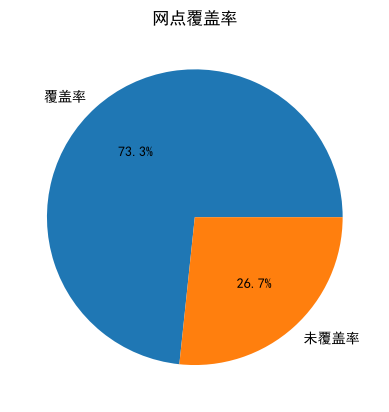

In [6]:
# q1
store_buffer = exist_gdfm.geometry.buffer(2000).union_all()
cover_s = cust_gdfm[cust_gdfm.geometry.within(store_buffer)]
uncover_s = cust_gdfm[~cust_gdfm.geometry.within(store_buffer)]
cover_rate = len(cover_s)/len(cust_gdfm)
uncover_rate = len(uncover_s)/len(cust_gdfm)
print(f"覆盖率{cover_rate}")
print(f"未覆盖率{uncover_rate}")
plt.pie([len(cover_s),len(uncover_s)],labels=["覆盖率","未覆盖率"],autopct="%.1f%%")
plt.title("网点覆盖率")
plt.show()
cover_sm = cover_s.to_crs("EPSG:3857")
m = folium.Map(location=[32,110],zoom_start=4)

# 店位置
for _,row in exist_gdfm.iterrows():
    folium.Marker(
        location=[row["lat"],row["lon"]],
        popup = f"门店:{row['store_id']}",
        icon=folium.Icon(color="blue", icon="store")
    ).add_to(m)

for _,row in cover_sm.iterrows():
    folium.CircleMarker(
        location=[row["lat"],row["lon"]],
        radius=4,
        popup=f"客户:{row['customer_id']}",
        color="red",fill=True,fill_opacity=0.6,fill_color="blue"
    ).add_to(m)
os.makedirs("maps1", exist_ok=True)
m.save("maps1/cover.html")
m

findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: 

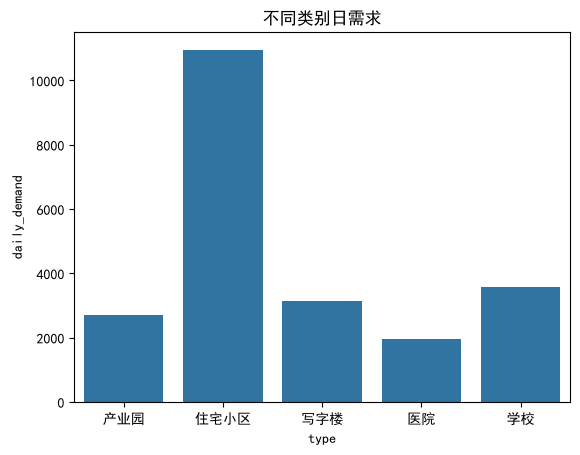

   type  daily_demand
0   产业园          2711
1  住宅小区         10950
2   写字楼          3137
3    医院          1952
4    学校          3563


In [7]:
# q2
t_stats = uncover_s.groupby("type")["daily_demand"].sum().reset_index()
sns.barplot(data=t_stats,x="type",y="daily_demand")
plt.title("不同类别日需求")
plt.show()
print(t_stats)

findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: 

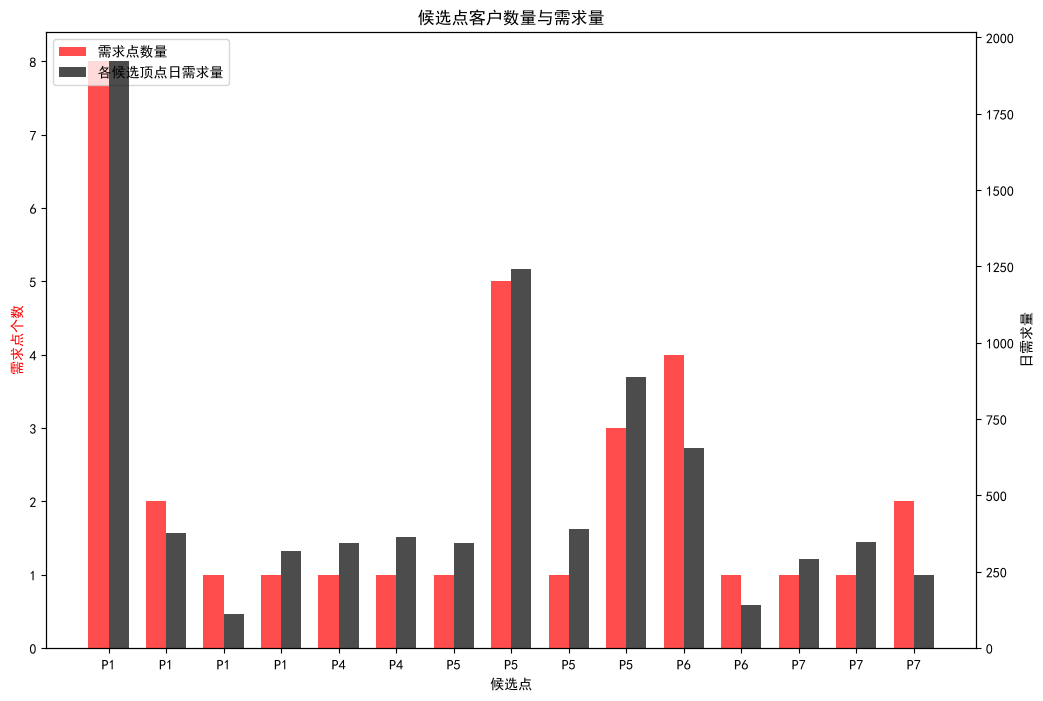

   candidate_id  type  customer_count  demand_cand
0            P1  住宅小区               8         1922
1            P1   写字楼               2          377
2            P1    医院               1          111
3            P1    学校               1          316
4            P4  住宅小区               1          343
5            P4    学校               1          365
6            P5   产业园               1          345
7            P5  住宅小区               5         1242
8            P5    医院               1          391
9            P5    学校               3          889
10           P6  住宅小区               4          655
11           P6    医院               1          140
12           P7   产业园               1          291
13           P7  住宅小区               1          347
14           P7   写字楼               2          240
    customer_id   lon_left  lat_left  type  daily_demand  \
44         C045  104.09679  30.69949  住宅小区           343   
45         C046  104.10072  30.55625   写字楼           310   
46  

In [8]:
# q3
cand_buffer_gdf = cand_gdfm.copy()
cand_buffer_gdf["geometry"] = cand_gdfm.geometry.buffer(2000)
join_res = gpd.sjoin(uncover_s,cand_buffer_gdf,how="inner",predicate="within")
cand_stats = join_res.groupby(["candidate_id","type"]).agg(customer_count = ("customer_id","count"),demand_cand=("daily_demand","sum")).reset_index()
fig,ax1 = plt.subplots(figsize=(12,8))
x = np.arange(len(cand_stats))
w = 0.35


ax1.bar(x - w/2, cand_stats["customer_count"], width=w, color="red",alpha=0.7,label="需求点数量")
ax1.set_xlabel("候选点")
ax1.set_ylabel("需求点个数",color="red")
ax1.tick_params(axis="y")
ax1.set_xticks(x)

ax1.set_xticklabels(cand_stats["candidate_id"])

ax2=ax1.twinx()
ax2.bar(x + w/2, cand_stats["demand_cand"], width=w, color="black",alpha=0.7,label="各候选顶点日需求量")
ax2.set_ylabel("日需求量", color="black")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
plt.title("候选点客户数量与需求量")
plt.savefig("cand_demand.png", dpi=150, bbox_inches="tight")
plt.show()
print(cand_stats)
print(join_res)


In [19]:
# q4 
exist_buffer_gdf = exist_gdfm.copy()
exist_buffer_gdf["geometry"] = exist_gdfm.geometry.buffer(2000)
exist_buffer_gdf["aov"] = exist_buffer_gdf["monthly_revenue"] / (exist_buffer_gdf["daily_orders"] * 30)
covered = gpd.sjoin(cust_gdfm, exist_buffer_gdf, predicate="within")
covered["pingxiao"] = covered["monthly_revenue"] / covered["area_sqm"]
type_stats = covered.groupby("type").agg(cover_stores=("store_id","nunique"),
     avg_revenue=("monthly_revenue","mean"),
     avg_pingxiao=("pingxiao","mean"),
    avg_aov = ("aov","mean")).reset_index()
print(type_stats)
print(covered.shape)

   type  cover_stores   avg_revenue  avg_pingxiao   avg_aov
0   产业园            36  26375.571429    231.283660  2.919897
1  住宅小区            41  27220.695489    237.802426  2.894345
2   写字楼            35  27908.526882    264.756622  2.969835
3    医院            29  26097.060000    237.131860  2.933126
4    学校            27  27637.250000    237.783151  3.000187
(516, 15)


In [21]:
# q5
cand_ruselt = cand_stats.merge(candidate_sites,on="candidate_id",how="outer")
ruselt = cand_ruselt.merge(t_stats,on="type",how="inner")
ruselt = ruselt.merge(type_stats[["type","avg_aov"]], on="type")
ruselt["est_monthly"] = ruselt["demand_cand"] * 30 * ruselt["avg_aov"]
final = cand_gdf.reset_index().merge(
    final.reset_index(), on="candidate_id", how="left"
)
final[["inc_demand","est_monthly","rent"]] = final[["inc_demand","est_monthly","rent"]].fillna(0)
final = ruselt.groupby("candidate_id").agg(
    inc_demand=("demand_cand", "sum"),        
    est_monthly=("est_monthly", "sum"),     
    rent=("monthly_rent", "first"))
final["net_est"] = final["est_monthly"] - final["rent"]
for m in [0.15, 0.25, 0.35]:
    final[f"profit_{m:.2f}"] = final["est_monthly"] * m - final["rent"]
final["breakeven_margin"] = final["rent"] / final["est_monthly"].replace(0, float("nan"))
print(final.sort_values("est_monthly", ascending=False))



              inc_demand    est_monthly   rent        net_est   profit_0.15  \
candidate_id                                                                  
P5                2867.0  252484.788954  25000  227484.788954  12872.718343   
P1                2726.0  238685.831317  18000  220685.831317  17802.874698   
P7                 878.0   77003.643440  19000   58003.643440  -7449.453484   
P6                 795.0   69193.001813  17000   52193.001813  -6621.049728   
P4                 708.0   62634.858694  20000   42634.858694 -10604.771196   

               profit_0.25   profit_0.35  breakeven_margin  
candidate_id                                                
P5            38121.197238  63369.676134          0.099016  
P1            41671.457829  65540.040961          0.075413  
P7              250.910860   7951.275204          0.246742  
P6              298.250453   7217.550634          0.245690  
P4            -4341.285326   1922.200543          0.319311  


## 现象 ：
现有 42 家门店 2km 覆盖率 73.3%（264/360 个需求点），96 个需求点未被覆盖（日需求 22,313）。8 个候选点中 5 个有增量覆盖，P2/P3/P8 圈内无未覆盖需求。

## 依据 ：
P5（日需求 2,867）与 P1（2,726）增量远高于 P7/P6/P4（700-900）。引入毛利率假设做敏感性分析：15%/25%/35% 三档下 P1 估算利润均为第一（1.78 万/4.17 万/6.55 万），P1 租金 18,000 低于 P5 的 25,000，保本毛利率仅 7.5%。

## 建议 ：
首选 P1——零售业合理毛利率区间（20-25%）内利润始终第一，且租金每月低 7,000 元；P5 需毛利率超 50.7% 才能反超，现实中难以达成，作备选。毛利率为外部行业假设而非数据推算，实际选址时应以真实供应链成本校准。


In [14]:

center_lat = cand_gdf.geometry.y.mean()
center_lon = cand_gdf.geometry.x.mean()

m1 = folium.Map(location=[center_lat, center_lon], zoom_start=11)
buffer_wgs = gpd.GeoSeries([store_buffer], crs="EPSG:3857").to_crs("EPSG:4326")

folium.GeoJson(
    buffer_wgs.to_json(),
    style_function=lambda x: {
        "color": "blue",
        "weight": 1.5,
        "fillColor": "#4287f5",
        "fillOpacity": 0.18
    }
).add_to(m1)

for _,row in exist_gdfm.iterrows():
    folium.Marker(
        location=[row["lat"],row["lon"]],
        popup = f"门店:{row['store_id']}",
        icon=folium.Icon(color="green", icon="store")
    ).add_to(m1)

for _,row in cand_gdfm.iterrows():
    folium.Marker(
        location=[row["lat"],row["lon"]],
        popup = f"候选点:{row['candidate_id']}",
        icon=folium.Icon(color="red", icon="user")
    ).add_to(m1)
    
for _,row in cust_gdfm.iterrows():
    folium.Marker(
        location=[row["lat"],row["lon"]],
        popup = f"需求点:{row['customer_id']}",
        icon=folium.Icon(color="black", icon="home")
    ).add_to(m1)

os.makedirs("maps2", exist_ok=True)
m1.save("maps2/candidate.html")
m1

store_buffer = exist_gdfm.geometry.buffer(2000).union_all()
uncover_s = cust_gdfm[~cust_gdfm.geometry.within(store_buffer)]

# 2. 转WGS84，folium必须4326
uncover_4326 = uncover_s.to_crs("EPSG:4326")

# 3. 盲区点均值做中心点，zoom=12
center_lat = uncover_4326.geometry.y.mean()
center_lon = uncover_4326.geometry.x.mean()
m_blind = folium.Map(location=[center_lat, center_lon], zoom_start=12)

# 4. 画盲区需求点（红色）
for _, row in uncover_4326.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=4,
        color="red",
        fill=True,
        fill_color="red",
        popup=f"类型:{row.type}, 日需求:{row.daily_demand}"
    ).add_to(m1)

# 5. 叠加原有门店2km缓冲区（蓝色虚线，参考边界）
store_4326 = exist_gdfm.to_crs("EPSG:4326")
for _, row in store_4326.iterrows():
    folium.Circle(
        location=[row.geometry.y, row.geometry.x],
        radius=2000,
        color="blue",
        fill=False,
        weight=2
    ).add_to(m1)

m1.save("maps2/blind_map.html")
m1

C:\Users\coo07\AppData\Local\Temp\ipykernel_19476\198290562.py:42: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  store_buffer = exist_gdfm.geometry.buffer(2000).unary_union
